In [54]:
#A. Understand the data:
#Import the dataset as a pandas dataframe 2. How does the data look like? 3. How big is the data? 4. What is the data type of each column? 5. How does the data look mathematically? 6. Are there any missing values? 7. Are there any duplicated rows? 8. List the 10 patients with the longest survival 9. List the 10 patients with the shortest survival 10. Find rows with null values and delete those rows.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
df=pd.read_csv('cirrhosis.csv')

In [6]:
df.head(6)

,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0
5,6,2503,D,Placebo,24201,F,N,Y,N,N,0.8,248.0,3.98,50.0,944.0,93.00,63.0,NaN,11.0,3.0


In [7]:
df.shape

(418, 20)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             418 non-null    int64  
 1   N_Days         418 non-null    int64  
 2   Status         418 non-null    str    
 3   Drug           312 non-null    str    
 4   Age            418 non-null    int64  
 5   Sex            418 non-null    str    
 6   Ascites        312 non-null    str    
 7   Hepatomegaly   312 non-null    str    
 8   Spiders        312 non-null    str    
 9   Edema          418 non-null    str    
 10  Bilirubin      418 non-null    float64
 11  Cholesterol    284 non-null    float64
 12  Albumin        418 non-null    float64
 13  Copper         310 non-null    float64
 14  Alk_Phos       312 non-null    float64
 15  SGOT           312 non-null    float64
 16  Tryglicerides  282 non-null    float64
 17  Platelets      407 non-null    float64
 18  Prothrombin    416 no

In [9]:
df.describe()

,ID,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
count,418.000000,418.000000,418.000000,418.000000,284.000000,418.000000,310.000000,312.000000,312.000000,282.000000,407.000000,416.000000,412.000000
mean,209.500000,1917.782297,18533.351675,3.220813,369.510563,3.497440,97.648387,1982.655769,122.556346,124.702128,257.024570,10.731731,3.024272
std,120.810458,1104.672992,3815.845055,4.407506,231.944545,0.424972,85.613920,2140.388824,56.699525,65.148639,98.325585,1.022000,0.882042
min,1.000000,41.000000,9598.000000,0.300000,120.000000,1.960000,4.000000,289.000000,26.350000,33.000000,62.000000,9.000000,1.000000
25%,105.250000,1092.750000,15644.500000,0.800000,249.500000,3.242500,41.250000,871.500000,80.600000,84.250000,188.500000,10.000000,2.000000
50%,209.500000,1730.000000,18628.000000,1.400000,309.500000,3.530000,73.000000,1259.000000,114.700000,108.000000,251.000000,10.600000,3.000000
75%,313.750000,2613.500000,21272.500000,3.400000,400.000000,3.770000,123.000000,1980.000000,151.900000,151.000000,318.000000,11.100000,4.000000
max,418.000000,4795.000000,28650.000000,28.000000,1775.000000,4.640000,588.000000,13862.400000,457.250000,598.000000,721.000000,18.000000,4.000000


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.corr(numeric_only=True)

,ID,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
ID,1.000000,-0.354305,0.037136,-0.062154,0.032897,-0.128924,-0.098663,-0.352856,-0.012097,-0.034100,-0.076699,-0.191930,-0.033757
N_Days,-0.354305,1.000000,-0.125934,-0.403953,-0.138236,0.430829,-0.364809,0.149269,-0.225492,-0.153000,0.151361,-0.111470,-0.366193
Age,0.037136,-0.125934,1.000000,0.002362,-0.157620,-0.182350,0.061549,-0.047247,-0.149869,0.022065,-0.148201,0.113760,0.189083
Bilirubin,-0.062154,-0.403953,0.002362,1.000000,0.397129,-0.314177,0.456918,0.116984,0.441730,0.436748,-0.013435,0.314894,0.200731
Cholesterol,0.032897,-0.138236,-0.157620,0.397129,1.000000,-0.069733,0.126115,0.149473,0.353246,0.276830,0.191710,-0.030811,0.011164
Albumin,-0.128924,0.430829,-0.182350,-0.314177,-0.069733,1.000000,-0.264771,-0.101456,-0.220047,-0.103417,0.158659,-0.200592,-0.305296
Copper,-0.098663,-0.364809,0.061549,0.456918,0.126115,-0.264771,1.000000,0.187357,0.293829,0.279852,-0.064403,0.218224,0.269400
Alk_Phos,-0.352856,0.149269,-0.047247,0.116984,0.149473,-0.101456,0.187357,1.000000,0.112217,0.180082,0.143733,0.089384,0.041273
SGOT,-0.012097,-0.225492,-0.149869,0.441730,0.353246,-0.220047,0.293829,0.112217,1.000000,0.126119,-0.120147,0.112174,0.164945
Tryglicerides,-0.034100,-0.153000,0.022065,0.436748,0.276830,-0.103417,0.279852,0.180082,0.126119,1.000000,0.103212,0.020122,0.123899


In [21]:
#List the 10 patients with the longest survival (N_Days)

In [12]:
print(df.nlargest(10, "N_Days")[["ID", "N_Days", "Status", "Stage", "Bilirubin"]])

      ID  N_Days Status  Stage  Bilirubin
324  325    4795      C    2.0        1.8
42    43    4556      C    2.0        1.1
31    32    4523      C    4.0        1.8
28    29    4509      C    2.0        0.7
1      2    4500      C    3.0        1.1
39    40    4467      C    4.0        1.3
57    58    4459      C    1.0        0.7
41    42    4453      C    4.0        2.1
47    48    4427      C    3.0        1.9
59    60    4365      C    3.0        0.9


In [20]:
#List the 10 patients with the shortest survival

In [13]:
print(df.nsmallest(10, "N_Days")[["ID", "N_Days", "Status", "Stage", "Bilirubin"]])

      ID  N_Days Status  Stage  Bilirubin
280  281      41      D    4.0       17.9
318  319      41      D    NaN        5.0
367  368      43      D    4.0       13.8
9     10      51      D    4.0       12.6
75    76      71      D    4.0       12.2
26    27      77      D    4.0       21.6
330  331      94      D    4.0        3.1
102  103     110      D    4.0        2.5
340  341     111      D    4.0        9.0
94    95     130      D    2.0       17.4


In [14]:
# age in years, readable status

In [15]:
df['Age_Years'] = (df['Age'] / 365.25).round(1)


In [16]:
df['Died'] = (df['Status'] == 'D').astype(int)

In [49]:
df.head(5)

,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,...,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Age_years,Age_Years,Died
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,...,156.0,1718.0,137.95,172.0,190.0,12.2,4.0,58.8,58.8,1
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,...,54.0,7394.8,113.52,88.0,221.0,10.6,3.0,56.4,56.4,0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,...,210.0,516.0,96.10,55.0,151.0,12.0,4.0,70.1,70.1,1
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,...,64.0,6121.8,60.63,92.0,183.0,10.3,4.0,54.7,54.7,1
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,...,143.0,671.0,113.15,72.0,136.0,10.9,3.0,38.1,38.1,0


In [31]:
#Find rows with null values and delete those rows

In [30]:
df[df.isnull().any(axis=1)]

,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage


In [17]:
df.isnull().sum()

ID                 0
N_Days             0
Status             0
Drug             106
Age                0
Sex                0
Ascites          106
Hepatomegaly     106
Spiders          106
Edema              0
Bilirubin          0
Cholesterol      134
Albumin            0
Copper           108
Alk_Phos         106
SGOT             106
Tryglicerides    136
Platelets         11
Prothrombin        2
Stage              6
Age_Years          0
Died               0
dtype: int64

In [24]:
df.dropna()

,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,...,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Age_Years,Died
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,...,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0,58.8,1
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,...,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0,56.4,0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,...,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0,70.1,1
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,...,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0,54.7,1
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,...,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0,38.1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,308,1153,C,D-penicillamine,22347,F,N,Y,N,N,...,3.58,24.0,797.0,91.00,113.0,288.0,10.4,2.0,61.2,0
308,309,994,C,Placebo,21294,F,N,N,N,N,...,2.75,41.0,1166.0,70.00,82.0,231.0,10.8,2.0,58.3,0
309,310,939,C,D-penicillamine,22767,F,N,N,N,N,...,3.35,39.0,1713.0,171.00,100.0,234.0,10.2,2.0,62.3,0
310,311,839,C,D-penicillamine,13879,F,N,N,N,N,...,3.16,69.0,1050.0,117.00,88.0,335.0,10.5,2.0,38.0,0


In [25]:
df.shape

(276, 22)

In [56]:
#B. Indexing and grouping
#1.Use the column Stage to create a separate DataFrame for each of the four stages.2.Find the mean follow-up days for each stage and sort them from lowest to highest?3.Compute the number of patients in each stage that have a bilirubin level above 3.0.

In [42]:
df_Stage = df.groupby('Stage')
df_Stage

In [30]:
print(df['Stage'].value_counts().sort_index())

Stage
1.0     12
2.0     59
3.0    111
4.0     94
Name: count, dtype: int64


In [44]:
df.groupby('Stage')['N_Days'].mean().sort_values(ascending=True)

Stage
4.0    1456.585106
3.0    2108.126126
2.0    2380.491525
1.0    2906.666667
Name: N_Days, dtype: float64

<Axes: xlabel='Stage', ylabel='count'>

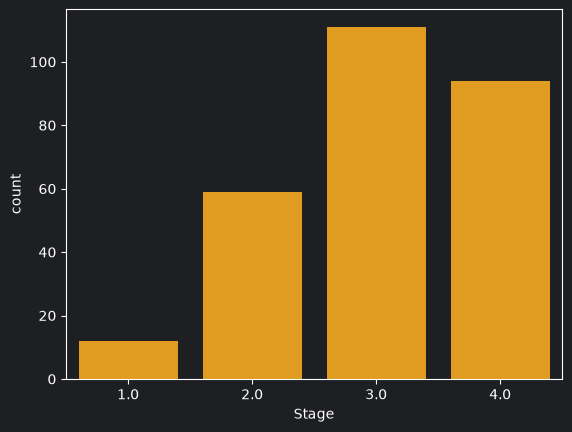

In [45]:
sns.countplot(x='Stage', data=df,color='orange')



In [46]:
df.groupby('Stage')['N_Days'].mean().sort_values(ascending=True)

Stage
4.0    1456.585106
3.0    2108.126126
2.0    2380.491525
1.0    2906.666667
Name: N_Days, dtype: float64

In [84]:
print(df[df["Bilirubin"] > 3.0].groupby("Stage").size())


Stage
1.0     2
2.0    18
3.0    36
4.0    64
dtype: int64


<Axes: xlabel='Bilirubin', ylabel='Count'>

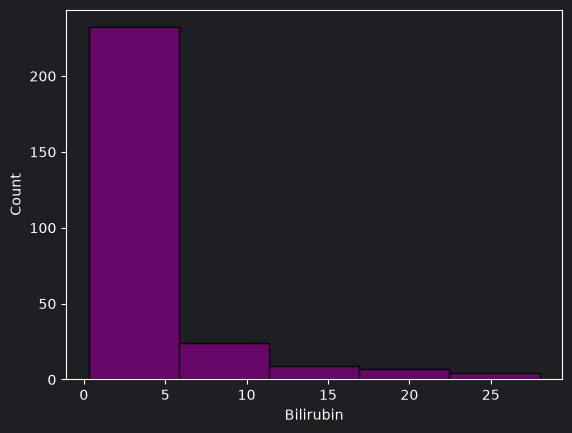

In [60]:
sns.histplot(data=df, x="Bilirubin",bins=5,color='purple')

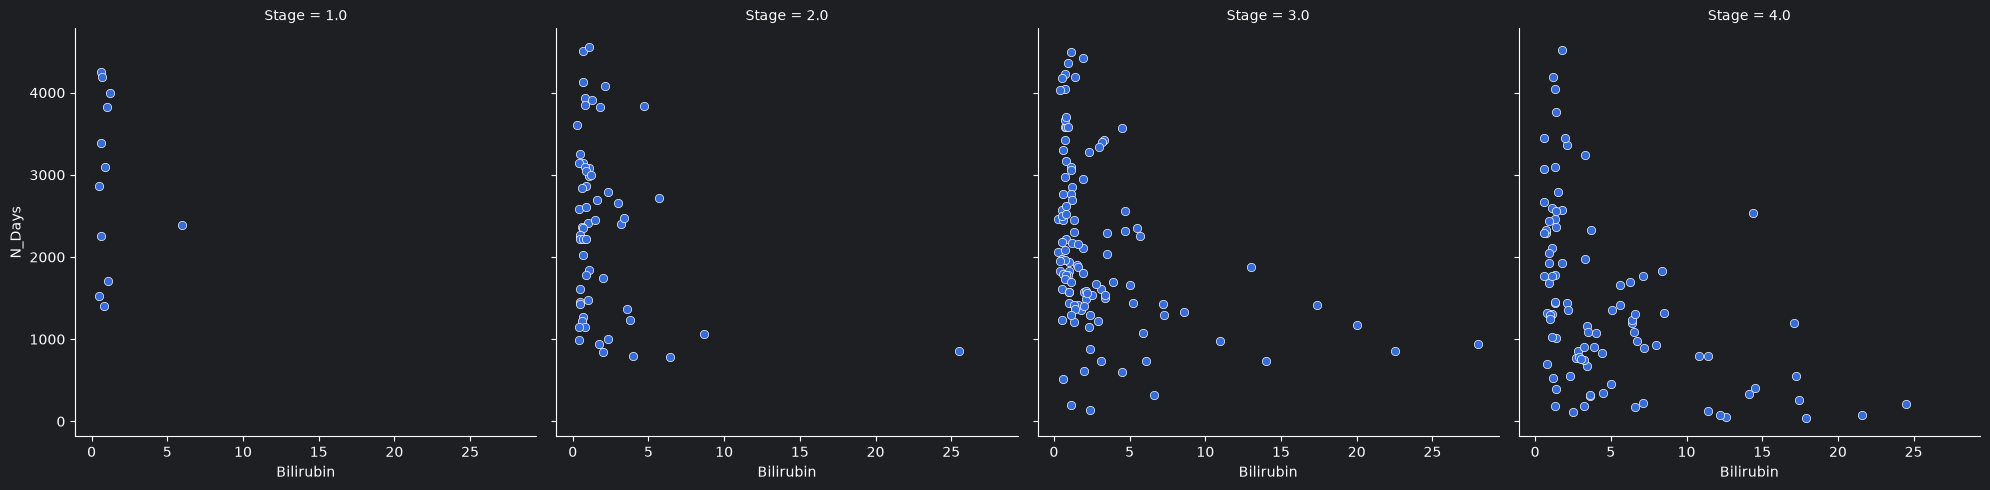

In [61]:
sns.relplot(data=df,x="Bilirubin",y="N_Days",kind="scatter",col="Stage")

In [ ]:
#C. Survival Analysis 1.Which patient has the longest Follow-up days?2.Which patient has the shortest Follow_up days?3.What is the average Follow up (in days) of all patients?

In [62]:
print(df.groupby("Status")["N_Days"].agg(["count", "mean", "min", "max"]).round(0))


        count    mean  min   max
Status                          
C         147  2392.0  788  4556
CL         18  1512.0  533  3092
D         111  1509.0   41  4191
